# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [2]:

# importar librerías
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [3]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')

users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')


In [7]:

# mostrar las primeras 5 filas de plans

plans.head()



,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [5]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [6]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [8]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [9]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [10]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [11]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [12]:

# cantidad de nulos para users
print("Cantidad de valores nulos en users:")
print(users.isna().sum())
print("\nProporción de valores nulos en users:")
print(users.isna().mean())

Cantidad de valores nulos en users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos en users:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [13]:
# cantidad de nulos para usage
print("\nCantidad de valores nulos en usage:")
print(usage.isna().sum())
print("\nProporción de valores nulos en usage:")
print(usage.isna().mean())


Cantidad de valores nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos en usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

-Users
  -city (0.11725 / ~11.73%): Investigar y marcar/imputar según corresponda, ya que está entre 5% y 30% y además presenta valores centinela como "?".   
  -churn_date (0.88350 / ~88.35%): Ignorar como campo de fecha faltante a imputar (conservar como indicador de usuario activo), dado que supera el 80% de nulos por lógica de negocio.
-usage
  -date (0.00125 / ~0.13%): Dejar como nulo o imputar con cuidado, ya que es menor al 5% y afecta solo a 50 de 40,000 registros.
  -duration (0.55190 / ~55.19%): Dejar como nulo según el tipo de evento, ya que corresponde a registros donde no aplica la duración de llamada (como mensajes).
  -length (0.44740 / ~44.74%): Dejar como nulo según el tipo de evento, ya que corresponde a registros donde no aplica la longitud del mensaje (como llamadas).
  

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [14]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` : tiene 4,000 registros completos que van de 10000 a 13999, con media y mediana de 11999.5 y desviación estándar de 1154.84. Es un identificador numérico correlativo y limpio, sin valores inválidos ni centinelas.
- La columna `age` : tiene 4,000 registros con mínimo de -999, cuartiles en 32 (25%), 47 (50%) y 63 (75%), máximo de 79, media de 33.74 y desviación estándar alta (123.23). El -999 es un valor centinela inválido (imposible como edad) que tira hacia abajo la media y infla la desviación estándar.

In [15]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- La columna user_id: tiene 40,000 registros (count), con un mínimo de 10,000.0 y un máximo de 13,999.0, media de 12,002.41, mediana de 12,013.0 y desviación estándar de 1,157.28. Coincide con el rango de identificadores de usuario sin valores inválidos ni centinelas
- La columna id: tiene 40,000 registros (count), con un mínimo de 1.0 y un máximo de 40,000.0, media y mediana de 20,000.5 y desviación estándar de 11,547.15. Funciona como un identificador numérico secuencial de cada registro de uso sin valores centinela ni rangos fuera de lo esperado.

In [16]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f"\nValores únicos en {col}:")
    print(users[col].unique())


Valores únicos en city:
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

Valores únicos en plan:
['Basico' 'Premium']


- La columna `city` ...
- La columna `plan` ...

In [17]:

# explorar columna categórica de usage
print(usage['type'].unique())
print("\nValores únicos en type:")


['call' 'text']

Valores únicos en type:


- La columna `type` ...
- En la columna type de usage se observan únicamente dos valores únicos: 'call' y 'text', sin valores nulos ni centinelas o categorías inválidas. Además, coincide con el comportamiento que vimos antes en los datos: 'call' se asocia a duration y 'text' a length.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

1. users['age'] — Valor centinela -999
Hallazgo: Tiene un valor mínimo de -999 frente a un rango válido observado entre 32 y 79 (mediana 47), lo cual es una edad imposible y distorsiona la media y la desviación estándar.
-Acción: Reemplazar -999 por NaN (o marcar/imputar según la regla de limpieza del proyecto) para que no sesgue los cálculos estadísticos ni las distribuciones de edad.

2. users['city'] — Valor centinela '?' (y formato/ausentes)
Hallazgo: Entre los valores únicos aparecen '?' y nan, además de ciudades como 'Medellin', 'Bogotá', 'CDMX', 'GDL', 'MTY' y 'Cali'.
-Acción: Convertir '?' a NaN (o a una categoría explícita de faltante/desconocida según la regla del análisis) y estandarizar nombres de ciudad si hace falta para evitar categorías duplicadas o mal etiquetadas.

3. usage['duration'] y usage['length'] — Valores en 0.0 (y máximos altos a revisar)
Hallazgo: Ambas columnas tienen un mínimo de 0.0 y máximos altos (120.0 en duration y 1490.0 en length).
-Acción: Verificar si 0.0 representa eventos reales sin duración/longitud o registros inválidos/centinela, y analizar los valores extremos en la etapa de outliers antes de decidir si se conservan, filtran o marcan.




### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [18]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')


In [19]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')


In [20]:
# Revisar los años presentes en `reg_date` de users
print("Años en users['reg_date']:")
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())


Años en users['reg_date']:
2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.
-Aparecen registros en 2022 (1,314), 2023 (1,316), 2024 (1,330) y 2026 (40), sumando los 4,000 usuarios sin NaN de conversión.
-El año 2026 (40 registros) está fuera del rango esperado (ya que el dataset tiene datos registrados hasta el año 2024), por lo que representa fechas anómalas/futuras respecto al corte del dataset que conviene revisar o limpiar según la regla del proyecto.


In [21]:

# Revisar los años presentes en `date` de usage
print("\nAños en usage['date']:")
print(usage['date'].dt.year.value_counts(dropna=False).sort_index())



Años en usage['date']:
2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

-La gran mayoría de los registros corresponden al año 2024 (39,950), y hay 50 valores NaN.

-Esos 50 NaN coinciden exactamente con los 50 valores faltantes que ya habíamos detectado en usage['date'], sin otros años fuera de rango en esta columna.



✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

¿Aparecen años imposibles? Sí: en users['reg_date'] aparecen 40 registros en el año 2026, mientras que los demás están entre 2022 y 2024 (y en usage['date'] solo aparece 2024 y 50 valores NaN, sin años fuera de rango). Dado que el dataset tiene registros hasta 2024, el año 2026 queda fuera del rango esperado (fuera del corte de 2024).

¿Qué harías con ellas? Convertir esos registros de 2026 en NaT (nulo de fecha) o filtrarlos/marcarlos según la regla de limpieza del proyecto para que no distorsionen análisis de antigüedad, cohortes ni ventanas temporales.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [22]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
print("Resumen de age tras limpieza:")
print(users['age'].describe())

Resumen de age tras limpieza:
count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


In [23]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print("\nValores únicos en city tras limpieza:")
print(users['city'].unique())
print("Nulos en city:", users['city'].isna().sum())



Valores únicos en city tras limpieza:
['Medellín' <NA> 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
Nulos en city: 565


In [24]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print("\nAños en reg_date tras limpieza:")
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())



Años en reg_date tras limpieza:
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [25]:
# Verificación MAR en usage (Missing At Random) para duration
print("Nulos en duration según type:")
print(usage.groupby('type')['duration'].apply(lambda s: s.isna().sum()))
print("\nProporción de nulos en duration según type:")
print(usage.groupby('type')['duration'].apply(lambda s: s.isna().mean()))


Nulos en duration según type:
type
call        0
text    22076
Name: duration, dtype: int64

Proporción de nulos en duration según type:
type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [26]:
# Verificación MAR en usage (Missing At Random) para length
print("\nNulos en length según type:")
print(usage.groupby('type')['length'].apply(lambda s: s.isna().sum()))
print("\nProporción de nulos en length según type:")
print(usage.groupby('type')['length'].apply(lambda s: s.isna().mean()))



Nulos en length según type:
type
call    17896
text        0
Name: length, dtype: int64

Proporción de nulos en length según type:
type
call    0.99933
text    0.00000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length

Diagnóstico de nulos en duration y length
Los nulos de duration y length dependen directamente de la columna type (call vs. text), lo que confirma un patrón MAR (Missing At Random) condicionado por el tipo de evento (las llamadas registran duration y no length, mientras que los mensajes de texto registran length y no duration).

Decisión: se dejan como nulos (NaN) y no se imputan (ni con ceros ni con medias/medianas), porque imputar duration en mensajes o length en llamadas introduciría datos artificiales y sesgaría las métricas de consumo de cada servicio.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [27]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id", as_index=False)
    .agg(
        cant_mensajes=("is_text", "sum"),
        cant_llamadas=("is_call", "sum"),
        cant_minutos_llamada=("duration", "sum"),
    )
)

# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [30]:

# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "cant_mensajes": "cant_mensajes",
    "cant_llamadas": "cant_llamadas",
    "cant_minutos_llamada": "cant_minutos_llamada",
})
# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [31]:
# Resumen estadístico de las columnas numéricas
cols_numericas = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols_numericas].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [32]:
# Distribución porcentual del tipo de plan
print("Distribución porcentual de plan:")
print(user_profile["plan"].value_counts(normalize=True) * 100)

Distribución porcentual de plan:
Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

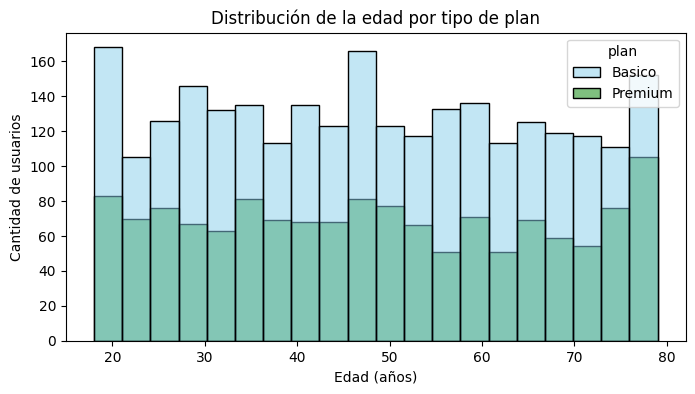

In [33]:


# Histograma para visualizar la edad (age)

plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="age", hue="plan", palette=["skyblue", "green"], bins=20, kde=False)
plt.title("Distribución de la edad por tipo de plan")
plt.xlabel("Edad (años)")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
- Distribución de la edad por tipo de plan 
Forma de la distribución: Tiene una distribución bastante uniforme / aproximadamente simétrica entre los 18 y 79 años, con media (48.14) y mediana (48.0) prácticamente iguales.
-Relación con el plan: No existe un patrón marcado de edad que separe a un plan de otro; ambos planes (Basico y Premium) están presentes en todos los rangos etarios, con mayor volumen absoluto en Basico porque representa cerca del 64.9% de los usuarios.

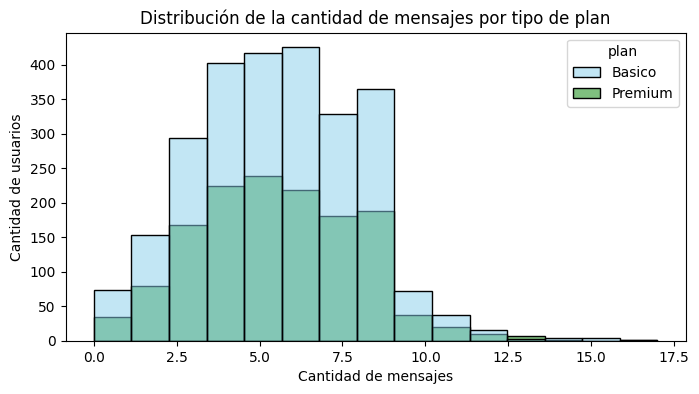

In [34]:

# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan", palette=["skyblue", "green"], bins=15, kde=False)
plt.title("Distribución de la cantidad de mensajes por tipo de plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
- Distribución de la cantidad de mensajes por tipo de plan 
Forma de la distribución: Presenta un leve sesgo a la derecha, concentrándose la mayoría de usuarios entre 3 y 8 mensajes (mediana 5.0, media 5.52) y con una cola larga hacia valores más altos (hasta 17 mensajes).
-Relación con el plan: Los usuarios Basico y Premium siguen un patrón de consumo similar en cuanto a la forma de la distribución, aunque el plan Basico concentra más usuarios en volumen total por su mayor proporción en la base.

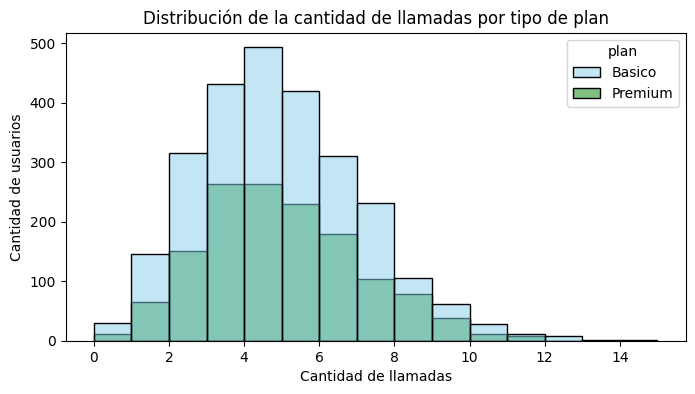

In [35]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan", palette=["skyblue", "green"], bins=15, kde=False)
plt.title("Distribución de la cantidad de llamadas por tipo de plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
-Distribución de la cantidad de llamadas por tipo de plan 
Forma de la distribución: Muestra una forma ligeramente sesgada a la derecha (cercana a unimodal), centrada alrededor de 4 a 5 llamadas (mediana 4.0, media 4.48) y extendiéndose hasta 15 llamadas.
-Relación con el plan: Ambos planes (Basico y Premium) muestran un comportamiento muy parecido en la cantidad de llamadas realizadas, sin una diferencia drástica en el patrón de frecuencia.

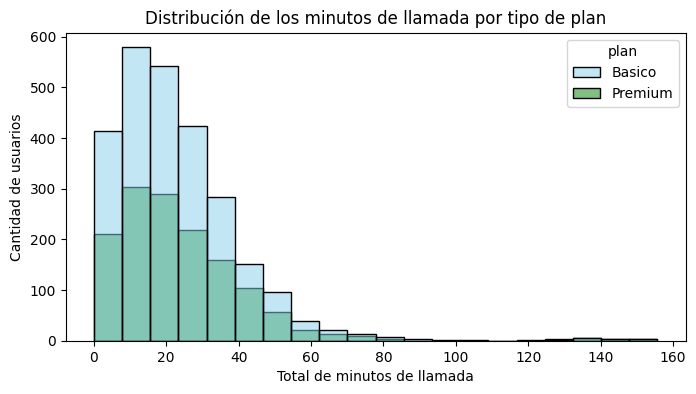

In [36]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan", palette=["skyblue", "green"], bins=20, kde=False)
plt.title("Distribución de los minutos de llamada por tipo de plan")
plt.xlabel("Total de minutos de llamada")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
-Distribución de los minutos de llamada por tipo de plan 
Forma de la distribución: Tiene un sesgo positivo (a la derecha) pronunciado, con la mayoría de usuarios concentrados entre 0 y 40 minutos (mediana 19.78, media 23.32) y una cola larga hacia valores altos que alcanzan cerca de 155.69 minutos.
-Relación con el plan: La mayoría de usuarios en ambos planes acumulan pocos minutos totales, mientras que un grupo minoritario de alto consumo tira de la cola derecha (incluyendo algunos registros altos visibles por encima de 120 minutos).

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

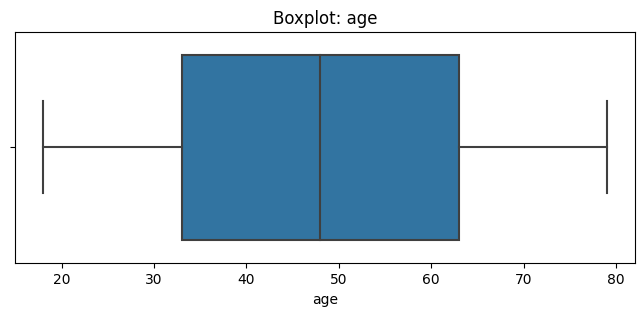

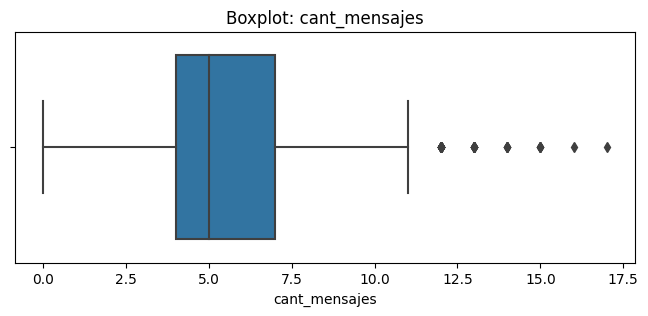

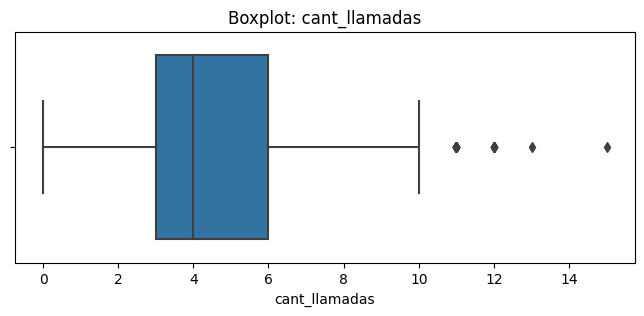

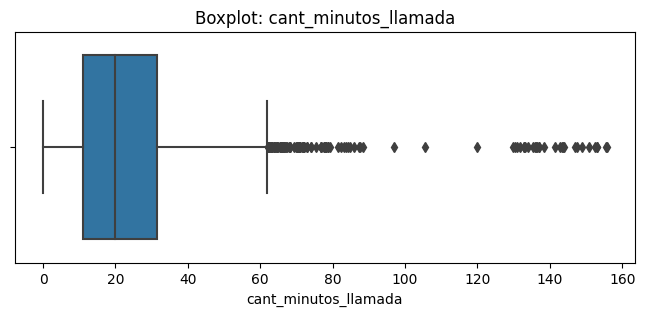

In [37]:

# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()


💡Insights: 
-age: no presenta outliers.
-cant_mensajes: sí presenta outliers por encima del bigote superior (valores altos hasta 17).
-cant_llamadas: sí presenta outliers por encima del bigote superior (valores altos hasta 15).
-cant_minutos_llamada: sí presenta outliers por encima del bigote superior (valores altos hasta 155.69).

In [38]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    print(f"{col} -> Q1: {q1:.2f}, Q3: {q3:.2f}, IQR: {iqr:.2f}, Límite superior: {limite_superior:.2f}, Max: {user_profile[col].max():.2f}")



cant_mensajes -> Q1: 4.00, Q3: 7.00, IQR: 3.00, Límite superior: 11.50, Max: 17.00
cant_llamadas -> Q1: 3.00, Q3: 6.00, IQR: 3.00, Límite superior: 10.50, Max: 15.00
cant_minutos_llamada -> Q1: 11.12, Q3: 31.41, IQR: 20.30, Límite superior: 61.86, Max: 155.69


In [39]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
   mantener los outliers, porque un máximo de 17 mensajes frente a un límite superior de 11.50 refleja usuarios de mayor actividad real de mensajería y no un error técnico evidente.
- cant_llamadas: mantener o no outliers, porqué?
   mantener los outliers, porque llegar a 15 llamadas frente a un límite superior de 10.50 representa un comportamiento plausible de usuarios con mayor frecuencia de llamadas en el periodo.
- cant_minutos_llamada: mantener o no outliers, porqué?
   mantener los outliers (o analizarlos como segmento de alto consumo), ya que llegar a 155.69 minutos frente a un límite superior de 61.86 corresponde a usuarios intensivos en llamadas que son clave para entender el consumo y las oportunidades de plan (aunque conviene usar la mediana al resumir tendencias centrales).

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [40]:
# Crear columna grupo_uso

def clasificar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)


In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [42]:
# Crear columna grupo_edad
def clasificar_edad(row):
    if row['age'] < 30:
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

In [45]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

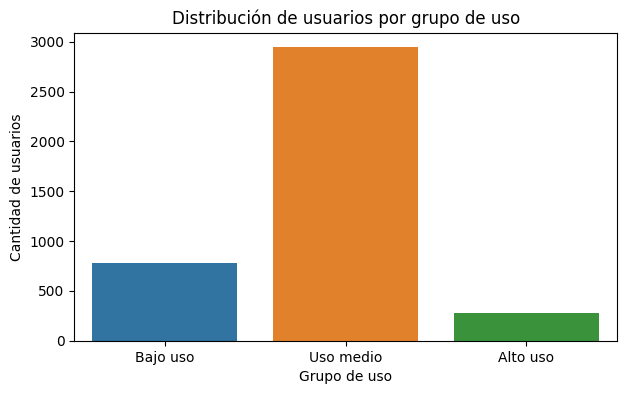

In [46]:
# Visualización de los segmentos por uso
plt.figure(figsize=(7, 4))
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'])
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

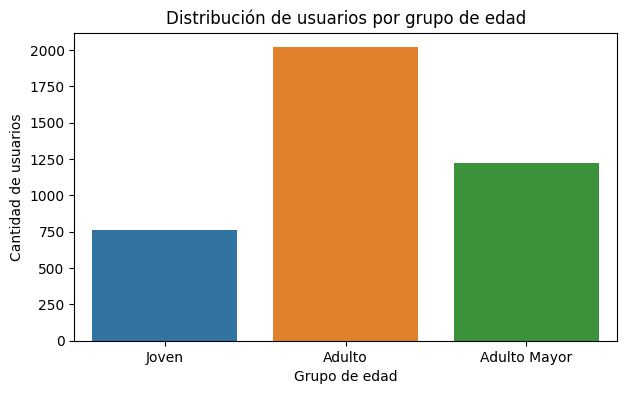

In [47]:
# Visualización de los segmentos por edad
plt.figure(figsize=(7, 4))
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'])
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
-En la tabla de usuarios (4,000 registros) se detectaron valores centinela y fechas inconsistentes: age contenía el valor centinela -999 (reemplazado por la mediana 48.0), city presentaba el centinela '?' (convertido a pd.NA), y reg_date incluía fechas futuras en 2026 (convertidas a NaT).

-En la tabla de uso (40,000 eventos de llamadas y mensajes) existían valores nulos en duration y length con un patrón Missing At Random (MAR) condicionado por el tipo de evento (call vs. text), por lo que se conservaron como NaN para evitar sesgos.


🔍 **Segmentos por Edad**
-Los clientes se agruparon en Joven (age < 30, unos 760 usuarios), Adulto (30 <= age < 60, cerca de 2,020 usuarios, el grupo mayoritario) y Adulto Mayor (age >= 60, alrededor de 1,220 usuarios). 
-La edad muestra una distribución uniforme/simétrica entre 18 y 79 años (media 48.14 y mediana 48.0) sin un sesgo marcado entre los planes Basico (~64.9%) y Premium (~35.1%).


📊 **Segmentos por Nivel de Uso**

-Al clasificar por llamadas y mensajes, la base se divide en Bajo uso (llamadas < 5 y mensajes < 5, unos 770 usuarios), Uso medio (llamadas < 10 y mensajes < 10 sin caer en el grupo anterior, cerca de 2,950 usuarios) y Alto uso (el resto de casos, unos 270 usuarios).
-Las métricas de actividad son unimodales y sesgadas a la derecha: cant_mensajes (mediana 5.0, límite superior IQR 11.50, máx. 17.0), cant_llamadas (mediana 4.0, límite superior IQR 10.50, máx. 15.0) y cant_minutos_llamada (mediana 19.78, límite superior IQR 61.86, máx. 155.69) presentan valores atípicos superiores reales que representan clientes de mayor consumo y se mantuvieron en el análisis.

➡️ Esto sugiere que ...los segmentos más valiosos para ConnectaTel son el grupo de Alto uso (por su intensidad de consumo y potencial de upselling/retención en planes superiores) y el núcleo de Uso medio concentrado en Adultos y Adultos Mayores (por su volumen y estabilidad), mientras que el plan Basico concentra cerca de dos tercios de la base y ofrece espacio para migrar usuarios de consumo creciente hacia Premium.


💡 **Recomendaciones**
- Migración y upselling desde Basico hacia Premium: ofrecer beneficios dirigidos a usuarios de Uso medio y Alto uso que hoy están en Basico (por ejemplo, bolsas extra de minutos o mensajes y ventajas de fidelidad) para elevar el ingreso promedio por usuario.
- Planes escalonados por perfil de consumo (y/o enfocadas en voz/mensajería): diseñar alternativas flexibles para los usuarios de Bajo uso (evitando que hagan churn por pagar de más) y paquetes específicos para usuarios intensivos en minutos y mensajes (outliers superiores) sin distorsionar las métricas centrales con promedios sesgados.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`